# 01 · Data exploration

Before building models I wanted to know how much there is to predict in daily NSE returns at all.
This notebook looks at the 10 stocks used in the project: price history, the shape of daily returns,
how much yesterday's return says about today's, volatility regimes and how much news coverage exists
over time.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import load_config, resolve_path

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
cfg = load_config()

In [2]:
from src.data.loader import load_ohlcv
from src.features.build import build_feature_frame

data = cfg["data"]
prices = {info["folder"]: load_ohlcv(t, resolve_path(data["raw_dir"]), data["period"], data["interval"])
          for t, info in cfg["tickers"].items()}
close = pd.DataFrame({k: v["Close"] for k, v in prices.items()}).dropna()
returns = np.log(close).diff().dropna()
print(f"{close.index[0].date()} -> {close.index[-1].date()}, {len(close)} trading days, {close.shape[1]} stocks")

2011-10-31 -> 2026-10-29, 3699 trading days, 10 stocks


## Price history

Growth of ₹1 since the start of the snapshot. All ten are large caps that did well over the period,
which is worth remembering later: buy & hold is a strong benchmark here (and the stock list itself has
survivorship bias, since these are today's large caps).

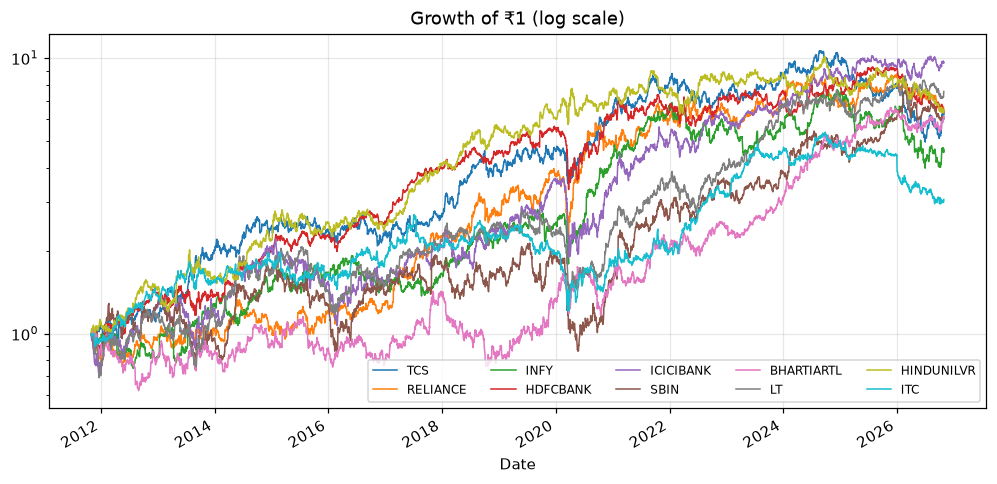

In [3]:
ax = (close / close.iloc[0]).plot(figsize=(11, 5), logy=True, lw=1)
ax.set_title("Growth of ₹1 (log scale)")
ax.legend(ncol=5, fontsize=8)
plt.show()

## Daily returns are fat-tailed

Kurtosis well above 3 means far more extreme days than a normal distribution would give. This is why
the neural nets use a Huber loss instead of plain MSE: a handful of ±8% days would otherwise dominate
training.

In [4]:
stats = pd.DataFrame({
    "mean %": returns.mean() * 100,
    "std %": returns.std() * 100,
    "skew": returns.skew(),
    "kurtosis": returns.kurt() + 3,
    "% up days": (returns > 0).mean() * 100,
    "worst day %": returns.min() * 100,
    "best day %": returns.max() * 100,
})
stats.round(2)

,mean %,std %,skew,kurtosis,% up days,worst day %,best day %
TCS,0.05,1.53,-0.05,7.18,50.92,-9.88,11.52
RELIANCE,0.05,1.68,0.07,9.78,51.14,-14.10,13.73
INFY,0.04,1.74,-1.06,22.09,51.62,-23.90,15.52
HDFCBANK,0.05,1.43,-0.20,11.06,51.14,-13.48,10.97
ICICIBANK,0.06,1.91,0.02,10.43,50.35,-19.66,13.70
SBIN,0.05,2.02,0.35,13.17,51.43,-15.55,24.44
BHARTIARTL,0.05,1.86,0.27,6.03,49.92,-12.73,10.70
LT,0.05,1.76,-0.14,9.75,49.78,-17.75,13.22
HINDUNILVR,0.05,1.44,0.91,12.74,49.89,-9.29,16.03
ITC,0.03,1.53,-0.69,12.80,50.62,-13.71,9.57


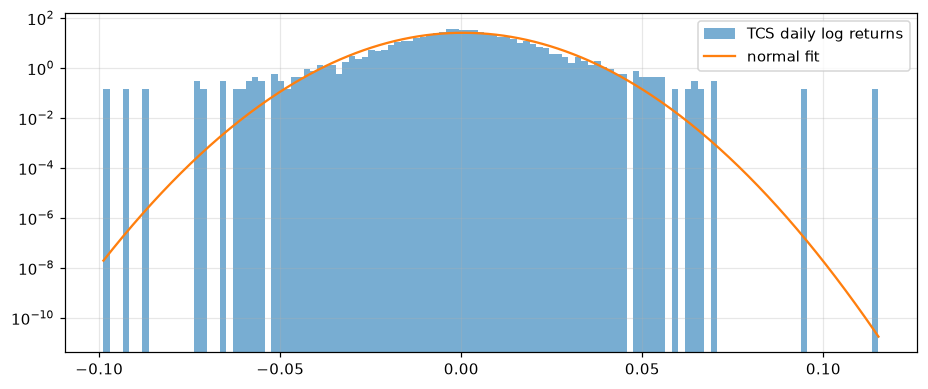

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
r = returns["TCS"]
ax.hist(r, bins=120, density=True, alpha=0.6, label="TCS daily log returns")
x = np.linspace(r.min(), r.max(), 400)
ax.plot(x, np.exp(-0.5 * ((x - r.mean()) / r.std()) ** 2) / (r.std() * np.sqrt(2 * np.pi)), label="normal fit")
ax.set_yscale("log")
ax.legend()
plt.show()

## Does yesterday predict today?

Autocorrelation of daily returns at lags 1-10. The dashed lines are the ±1.96/√n band; values inside
it are indistinguishable from zero.

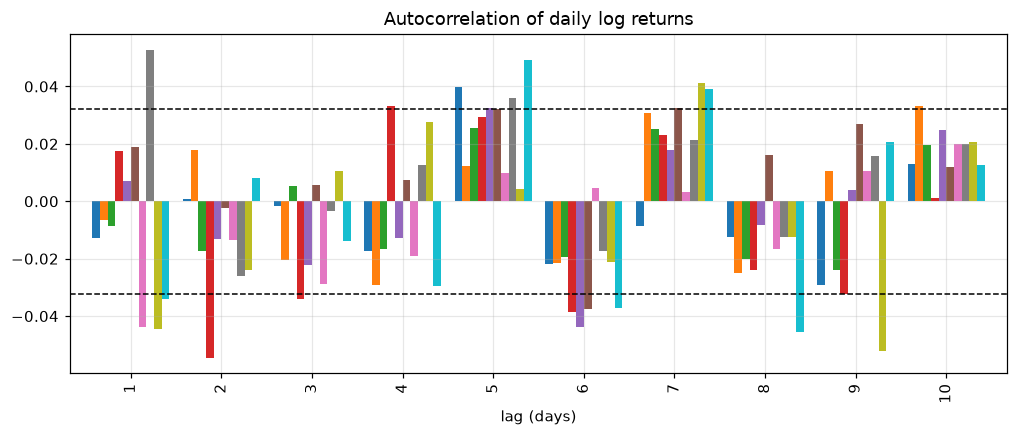

share of (stock, lag) pairs outside the band: 22% (5% expected by chance)
largest |autocorrelation|: 0.054  ->  explains 0.30% of variance


In [6]:
from statsmodels.tsa.stattools import acf

lags = range(1, 11)
ac = pd.DataFrame({s: acf(returns[s], nlags=10)[1:] for s in returns}, index=lags)
band = 1.96 / np.sqrt(len(returns))
ax = ac.plot(kind="bar", figsize=(11, 4), width=0.85, legend=False)
ax.axhline(band, ls="--", c="k", lw=1)
ax.axhline(-band, ls="--", c="k", lw=1)
ax.set_xlabel("lag (days)")
ax.set_title("Autocorrelation of daily log returns")
plt.show()
outside = (ac.abs() > band).to_numpy().mean()
largest = ac.abs().to_numpy().max()
print(f"share of (stock, lag) pairs outside the band: {outside:.0%} (5% expected by chance)")
print(f"largest |autocorrelation|: {largest:.3f}  ->  explains {largest ** 2:.2%} of variance")

More lags fall outside the band than chance alone would give, so returns are not perfectly
independent. But the effects are tiny (the largest explains well under 1% of the next day's variance)
and their sign changes from stock to stock. That is far too little to trade after costs, and it is why
ARIMA ends up close to "predict the mean".

## Volatility regimes

20-day rolling volatility (annualised). March 2020 stands out for every stock. The walk-forward test
period (Sep 2020 onwards) starts just after it, so the models are trained across very different regimes.

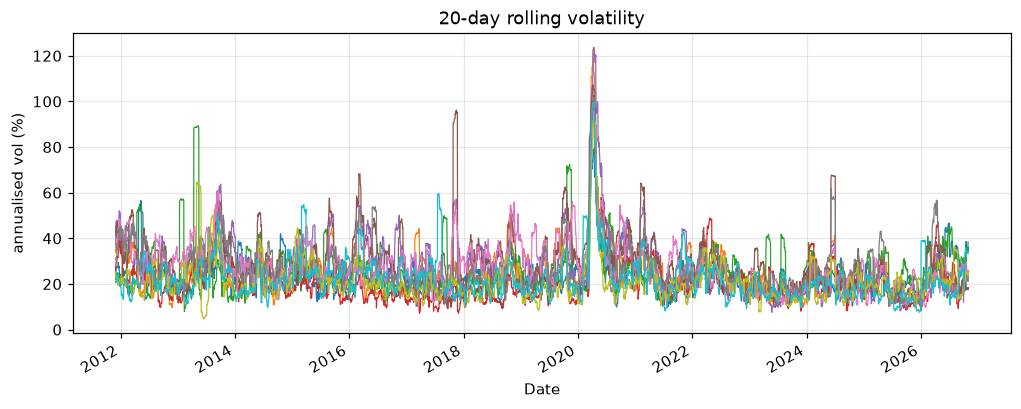

In [7]:
vol = returns.rolling(20).std() * np.sqrt(252) * 100
ax = vol.plot(figsize=(11, 4), lw=0.8, legend=False)
ax.set_ylabel("annualised vol (%)")
ax.set_title("20-day rolling volatility")
plt.show()

## The model features

The models never see raw prices, only stationary transforms (returns, ratios, distances from moving
averages). A quick check that each feature is stable over time and what its correlation with the
next-day return looks like.

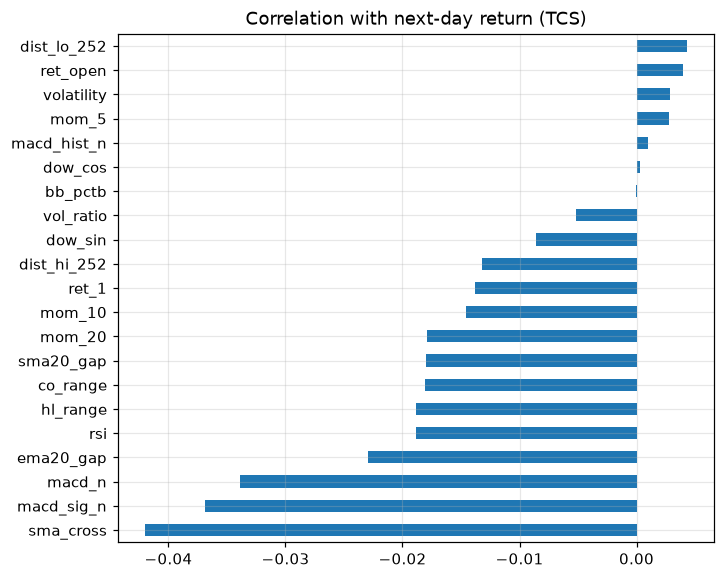

largest |corr|: 0.042


In [8]:
frame = build_feature_frame(prices["TCS"])
corr = frame.drop(columns=["close"]).corr()["target"].drop("target").sort_values()
ax = corr.plot(kind="barh", figsize=(7, 6))
ax.set_title("Correlation with next-day return (TCS)")
plt.show()
print(f"largest |corr|: {corr.abs().max():.3f}")

## News coverage over time

Headlines come from a weekly Google News backfill (`python -m src.data.news`). Coverage grows a lot
over time, so the news features are much sparser in the early training years than in the test years.

In [9]:
from src.data.news import RAW_DIR, load_headlines

counts = {}
for info in cfg["tickers"].values():
    h = load_headlines(info["folder"], resolve_path(RAW_DIR))
    counts[info["folder"]] = h.groupby(h["published"].dt.year).size()
coverage = pd.DataFrame(counts).fillna(0).astype(int)
coverage.loc["total"] = coverage.sum()
coverage

,TCS,RELIANCE,INFY,HDFCBANK,ICICIBANK,SBIN,BHARTIARTL,LT,HINDUNILVR,ITC
published,,,,,,,,,,
2011,5,43,18,12,19,8,30,5,12,0
2012,37,247,159,152,154,72,252,20,100,4
2013,72,363,246,225,262,113,333,36,229,3
2014,65,370,255,244,242,112,281,48,168,3
2015,71,365,332,324,311,142,365,57,252,7
2016,110,393,362,337,372,294,370,93,286,5
2017,143,390,458,414,369,370,425,119,321,14
2018,163,415,380,427,463,409,420,144,325,11
2019,203,485,405,510,466,458,450,193,305,28


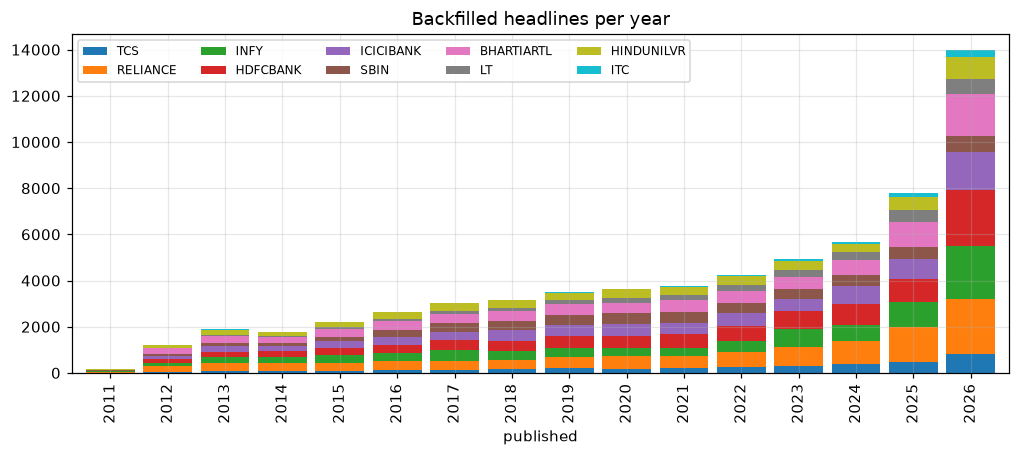

In [10]:
ax = coverage.drop("total").plot(kind="bar", stacked=True, figsize=(11, 4), width=0.85)
ax.set_title("Backfilled headlines per year")
ax.legend(ncol=5, fontsize=8)
plt.show()

## Takeaways

* Daily returns are close to unpredictable from their own past: autocorrelations are tiny and
  inconsistent across stocks, and the single best feature correlates with the next day's return at
  only a few hundredths.
* Fat tails need a robust loss and honest metrics (direction accuracy with p-values, strategy returns
  after costs) rather than price MAPE, which a random walk already gets to ~1%.
* News coverage is uneven over time, which limits what a news feature can add in the early folds.